In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import random
import time
import warnings
from datetime import datetime

import torch
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from PIL import Image

warnings.filterwarnings("ignore")

In [2]:
def seed_everything(seed):
    """Mengatur seed untuk reproduktifitas."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(42)

In [3]:
hyperparameters = {
    'num_classes': 2,
    'learning_rate': 1e-4,
    'img_size': 224, 
    'batch_size': 32,
    'n_epochs': 25,
    'data_path': r'../../dataset/OralCancer_DatasetGabungan',
}

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
def load_data_from_folders(data_path):
    """Memuat path gambar dan label dari struktur folder."""
    image_paths = []
    labels = []
    class_map = {'Cancer': 1, 'Non-Cancer': 0}
    
    for class_name, label in class_map.items():
        class_dir = os.path.join(data_path, class_name)
        if not os.path.isdir(class_dir):
            print(f"Warning: Folder '{class_dir}' tidak ditemukan.")
            continue
        for img_name in os.listdir(class_dir):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_paths.append(os.path.join(class_dir, img_name))
                labels.append(label)
                
    return image_paths, labels

all_image_paths, all_labels = load_data_from_folders(hyperparameters['data_path'])

if not all_image_paths:
    raise ValueError("Tidak ada gambar yang ditemukan. Periksa 'data_path' dan struktur folder Anda.")

In [6]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_image_paths, all_labels, test_size=0.3, random_state=42, stratify=all_labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

print(f"Total gambar: {len(all_image_paths)}")
print(f"Data Latih: {len(train_paths)} sampel")
print(f"Data Validasi: {len(val_paths)} sampel")
print(f"Data Uji: {len(test_paths)} sampel")

Total gambar: 1690
Data Latih: 1183 sampel
Data Validasi: 253 sampel
Data Uji: 254 sampel


In [7]:
import collections

# Cek distribusi kelas SEBELUM oversampling
print("Distribusi data latih SEBELUM oversampling:")
label_counts_before = collections.Counter(train_labels)
print(f"  - Non-Cancer (0): {label_counts_before[0]} sampel")
print(f"  - Cancer (1): {label_counts_before[1]} sampel")

# Tentukan kelas minoritas dan mayoritas
minority_class_label = 0  # Non-Cancer
majority_class_label = 1  # Cancer

count_majority = label_counts_before[majority_class_label]
count_minority = label_counts_before[minority_class_label]

# Jika kelas Non-Cancer adalah minoritas, lakukan oversampling
if count_minority < count_majority:
    # Hitung berapa banyak sampel yang perlu ditambahkan
    num_to_add = count_majority - count_minority
    print(f"\nKelas 'Non-Cancer' adalah minoritas. Menambahkan {num_to_add} sampel...")

    # Dapatkan path dan label dari semua sampel kelas minoritas
    minority_paths = [path for path, label in zip(train_paths, train_labels) if label == minority_class_label]
    
    # Pilih secara acak sampel dari kelas minoritas untuk diduplikasi (dengan replacement)
    oversampled_paths_to_add = random.choices(minority_paths, k=num_to_add)
    oversampled_labels_to_add = [minority_class_label] * num_to_add

    # Tambahkan sampel yang telah diduplikasi ke data latih
    train_paths.extend(oversampled_paths_to_add)
    train_labels.extend(oversampled_labels_to_add)

    # **PENTING**: Kocok (shuffle) kembali data latih agar sampel duplikat terdistribusi acak
    temp_combined = list(zip(train_paths, train_labels))
    random.shuffle(temp_combined)
    train_paths, train_labels = zip(*temp_combined)
    
    # Konversi kembali ke list
    train_paths = list(train_paths)
    train_labels = list(train_labels)

    # Cek distribusi kelas SETELAH oversampling
    print("\nDistribusi data latih SETELAH oversampling:")
    label_counts_after = collections.Counter(train_labels)
    print(f"  - Non-Cancer (0): {label_counts_after[0]} sampel")
    print(f"  - Cancer (1): {label_counts_after[1]} sampel")
    print(f"Total data latih baru: {len(train_paths)} sampel")

else:
    print("\nJumlah data latih sudah seimbang atau kelas 'Non-Cancer' bukan minoritas. Tidak ada oversampling yang dilakukan.")

Distribusi data latih SEBELUM oversampling:
  - Non-Cancer (0): 490 sampel
  - Cancer (1): 693 sampel

Kelas 'Non-Cancer' adalah minoritas. Menambahkan 203 sampel...

Distribusi data latih SETELAH oversampling:
  - Non-Cancer (0): 693 sampel
  - Cancer (1): 693 sampel
Total data latih baru: 1386 sampel


In [8]:
class OralCancerDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        
        try:
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
        except Exception as e:
            print(f"Gagal memuat atau mentransformasi gambar: {img_path}. Error: {e}")
            # Mengembalikan tensor kosong jika terjadi kesalahan
            return torch.zeros((3, hyperparameters['img_size'], hyperparameters['img_size'])), label

        return image, label

In [9]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(hyperparameters['img_size'], scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_test_transform = transforms.Compose([
    transforms.Resize((hyperparameters['img_size'], hyperparameters['img_size'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [10]:
train_dataset = OralCancerDataset(train_paths, train_labels, transform=train_transform)
val_dataset = OralCancerDataset(val_paths, val_labels, transform=val_test_transform)
test_dataset = OralCancerDataset(test_paths, test_labels, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=hyperparameters['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=hyperparameters['batch_size'], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=hyperparameters['batch_size'], shuffle=False)

print(f'Ukuran Train loader: {len(train_loader)}')
print(f'Ukuran Validation loader: {len(val_loader)}')
print(f'Ukuran Test loader: {len(test_loader)}')

Ukuran Train loader: 44
Ukuran Validation loader: 8
Ukuran Test loader: 8


In [11]:
model = models.mobilenet_v2(pretrained=True)

# 1. Bekukan parameter di lapisan fitur (konvolusi)
for param in model.features.parameters():
    param.requires_grad = False

num_ftrs = model.classifier[1].in_features # -> 1280 untuk MobileNetV2

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3), # Menggunakan dropout untuk regularisasi
    nn.Linear(num_ftrs, hyperparameters['num_classes'])
)

# Pindahkan model ke device (GPU atau CPU)
model = model.to(device)

# Cetak untuk verifikasi (opsional)
print("Arsitektur classifier MobileNetV2 yang baru:")
print(model.classifier)

Arsitektur classifier MobileNetV2 yang baru:
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=hyperparameters['learning_rate'],
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

In [13]:
def train_and_validate_model(model, train_loader, val_loader, criterion, optimizer, scheduler, hyperparameters, patience=5):
    total_start_time = time.time()
    best_val_loss = float('inf')
    patience_counter = 0

    base_folder = "../../models"
    checkpoint_folder = os.path.join(base_folder, "checkpoints")
    os.makedirs(checkpoint_folder, exist_ok=True)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(hyperparameters['n_epochs']):
        epoch_start_time = time.time()
        
        # Training Phase
        model.train()
        total_train_loss, total_train_correct = 0.0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * inputs.size(0)
            total_train_correct += (outputs.argmax(1) == labels).sum().item()

        avg_train_loss = total_train_loss / len(train_loader.dataset)
        train_accuracy = total_train_correct / len(train_loader.dataset) * 100
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_accuracy)

        # Validation Phase
        model.eval()
        total_val_loss, total_val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                total_val_loss += loss.item() * inputs.size(0)
                total_val_correct += (outputs.argmax(1) == labels).sum().item()

        avg_val_loss = total_val_loss / len(val_loader.dataset)
        val_accuracy = total_val_correct / len(val_loader.dataset) * 100
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_accuracy)

        scheduler.step(avg_val_loss)
        epoch_time = time.time() - epoch_start_time
        
        print(f'Epoch {epoch + 1}/{hyperparameters["n_epochs"]} | '
              f'Train Loss: {avg_train_loss:.4f}, Acc: {train_accuracy:.2f}% | '
              f'Val Loss: {avg_val_loss:.4f}, Acc: {val_accuracy:.2f}% | '
              f'Time: {epoch_time:.2f}s')

        # Saving the best model
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            timestamp = datetime.now().strftime("%Y%m%d")
            best_model_path = os.path.join(checkpoint_folder, f'ResNet50_best_model_{timestamp}.pth')
            torch.save(model.state_dict(), best_model_path)
            print(f"Validation loss improved. Saving model to {best_model_path}")
        else:
            patience_counter += 1
            print(f'No improvement. Patience: {patience_counter}/{patience}')

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    total_training_time = time.time() - total_start_time
    print(f'Total Training Time: {total_training_time / 60:.2f} minutes')
    return history

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [15]:
def evaluate_model(model, test_loader):
    """Evaluasi model pada test set."""
    model.eval()
    all_preds = []
    all_labels = []
    test_correct = 0
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            test_correct += (preds == labels).sum().item()
    
    test_accuracy = test_correct / len(test_loader.dataset) * 100
    print(f"Test Accuracy: {test_accuracy:.2f}%")
    
    return all_preds, all_labels, test_accuracy

In [16]:
def plot_confusion_matrix(y_true, y_pred, class_names):
    """Plot confusion matrix dengan matplotlib."""
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Membuat heatmap manual
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.figure.colorbar(im, ax=ax)
    
    # Set ticks
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           xticklabels=class_names,
           yticklabels=class_names,
           title='Confusion Matrix',
           ylabel='True Label',
           xlabel='Predicted Label')
    
    # Rotate tick labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    # Menambahkan text annotations
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm[i, j]}\n({cm_normalized[i, j]:.1f}%)',
                   ha="center", va="center",
                   color="white" if cm[i, j] > thresh else "black",
                   fontsize=12)
    
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return cm

In [17]:
def calculate_metrics(y_true, y_pred, class_names):
    """Menghitung dan menampilkan berbagai metrik evaluasi."""
    cm = confusion_matrix(y_true, y_pred)
    
    # Menghitung metrik per kelas
    tn, fp, fn, tp = cm.ravel()
    
    # Metrik untuk kelas positif (Cancer)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0  # Recall/Sensitivity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1_score = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    print("\n" + "="*50)
    print("HASIL EVALUASI MODEL")
    print("="*50)
    
    print(f"\nOverall Accuracy: {accuracy*100:.2f}%")
    print(f"\nUntuk Kelas 'Cancer' (Positive Class):")
    print(f"  - Sensitivity (Recall): {sensitivity*100:.2f}%")
    print(f"  - Specificity: {specificity*100:.2f}%")
    print(f"  - Precision: {precision*100:.2f}%")
    print(f"  - F1-Score: {f1_score*100:.2f}%")
    
    print(f"\nConfusion Matrix Details:")
    print(f"  - True Positives (Cancer detected correctly): {tp}")
    print(f"  - True Negatives (Non-Cancer detected correctly): {tn}")
    print(f"  - False Positives (Non-Cancer misclassified as Cancer): {fp}")
    print(f"  - False Negatives (Cancer misclassified as Non-Cancer): {fn}")
    
    # Classification report
    print("\n" + "="*50)
    print("CLASSIFICATION REPORT")
    print("="*50)
    print(classification_report(y_true, y_pred, target_names=class_names))
    
    return {
        'accuracy': accuracy,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': precision,
        'f1_score': f1_score,
        'confusion_matrix': cm
    }

In [18]:
def visualize_predictions(model, test_dataset, num_samples=8):
    """Visualisasi beberapa sampel prediksi."""
    model.eval()
    class_names = ['Non-Cancer', 'Cancer']
    
    # Ambil sampel random
    indices = random.sample(range(len(test_dataset)), min(num_samples, len(test_dataset)))
    
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    axes = axes.ravel()
    
    with torch.no_grad():
        for idx, i in enumerate(indices):
            if idx >= len(axes):
                break
                
            image, true_label = test_dataset[i]
            image_display = image.clone()
            
            # Denormalisasi untuk display
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
            image_display = image_display * std + mean
            image_display = torch.clamp(image_display, 0, 1)
            
            # Prediksi
            image = image.unsqueeze(0).to(device)
            output = model(image)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            _, pred = torch.max(output, 1)
            
            # Plot
            axes[idx].imshow(image_display.permute(1, 2, 0))
            axes[idx].axis('off')
            
            true_class = class_names[true_label]
            pred_class = class_names[pred.item()]
            prob = probabilities[0][pred.item()].item() * 100
            
            color = 'green' if true_label == pred.item() else 'red'
            axes[idx].set_title(f'True: {true_class}\nPred: {pred_class} ({prob:.1f}%)', 
                               color=color, fontsize=10)
    
    plt.tight_layout()
    plt.savefig('sample_predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

Epoch 1/25 | Train Loss: 0.6956, Acc: 53.75% | Val Loss: 0.6081, Acc: 72.83% | Time: 39.02s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250703.pth
Epoch 2/25 | Train Loss: 0.6210, Acc: 65.66% | Val Loss: 0.5466, Acc: 79.92% | Time: 38.60s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250703.pth
Epoch 3/25 | Train Loss: 0.5578, Acc: 72.94% | Val Loss: 0.5108, Acc: 81.89% | Time: 38.37s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250703.pth
Epoch 4/25 | Train Loss: 0.5167, Acc: 77.13% | Val Loss: 0.4626, Acc: 81.10% | Time: 39.54s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250703.pth
Epoch 5/25 | Train Loss: 0.4929, Acc: 78.72% | Val Loss: 0.4610, Acc: 81.89% | Time: 38.99s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250703.pth
Epoch

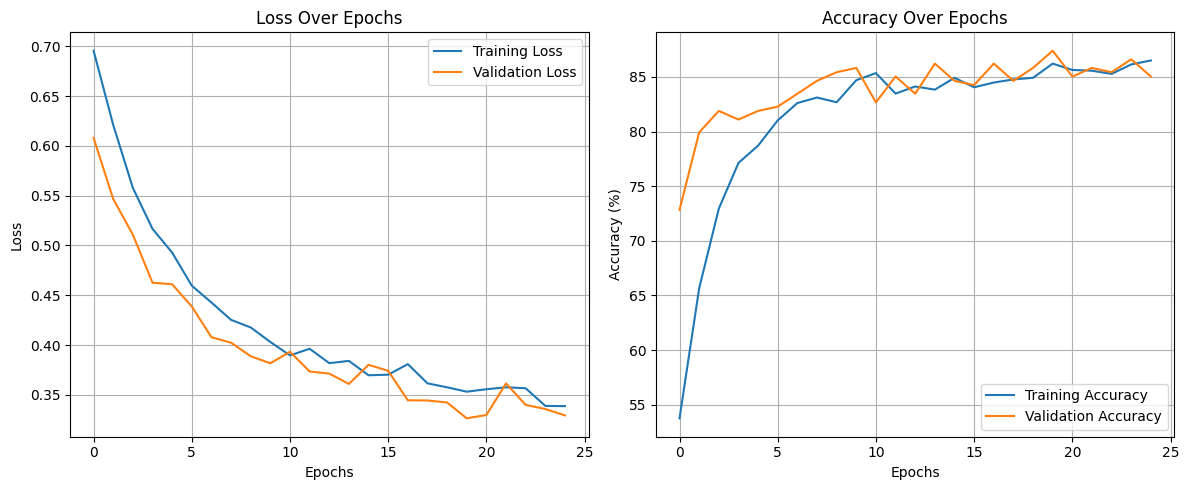


EVALUASI MODEL PADA TEST SET
Gagal memuat atau mentransformasi gambar: C:\Pytorch_project\OralCancer_DatasetGabungan\Cancer\CANCER_V2_455.jpeg. Error: cannot identify image file 'C:\\Pytorch_project\\OralCancer_DatasetGabungan\\CANCER\\CANCER_V2_455.jpeg'
Test Accuracy: 86.22%


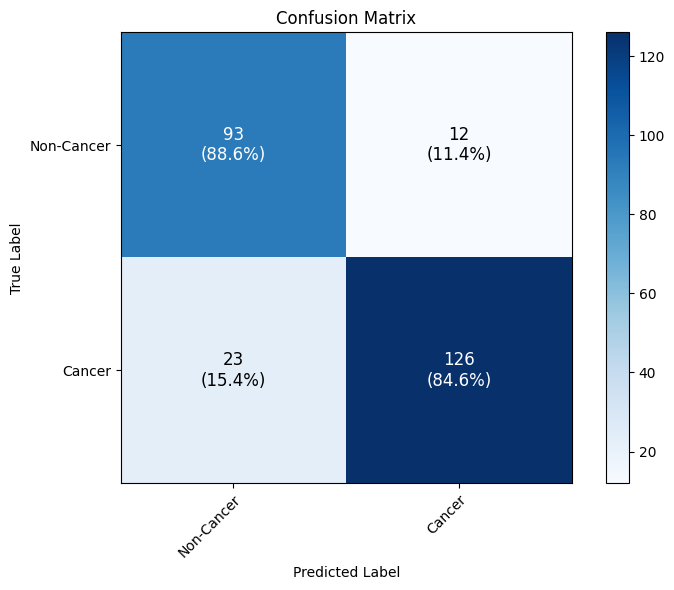


HASIL EVALUASI MODEL

Overall Accuracy: 86.22%

Untuk Kelas 'Cancer' (Positive Class):
  - Sensitivity (Recall): 84.56%
  - Specificity: 88.57%
  - Precision: 91.30%
  - F1-Score: 87.80%

Confusion Matrix Details:
  - True Positives (Cancer detected correctly): 126
  - True Negatives (Non-Cancer detected correctly): 93
  - False Positives (Non-Cancer misclassified as Cancer): 12
  - False Negatives (Cancer misclassified as Non-Cancer): 23

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Non-Cancer       0.80      0.89      0.84       105
      Cancer       0.91      0.85      0.88       149

    accuracy                           0.86       254
   macro avg       0.86      0.87      0.86       254
weighted avg       0.87      0.86      0.86       254


Membuat visualisasi sampel prediksi...


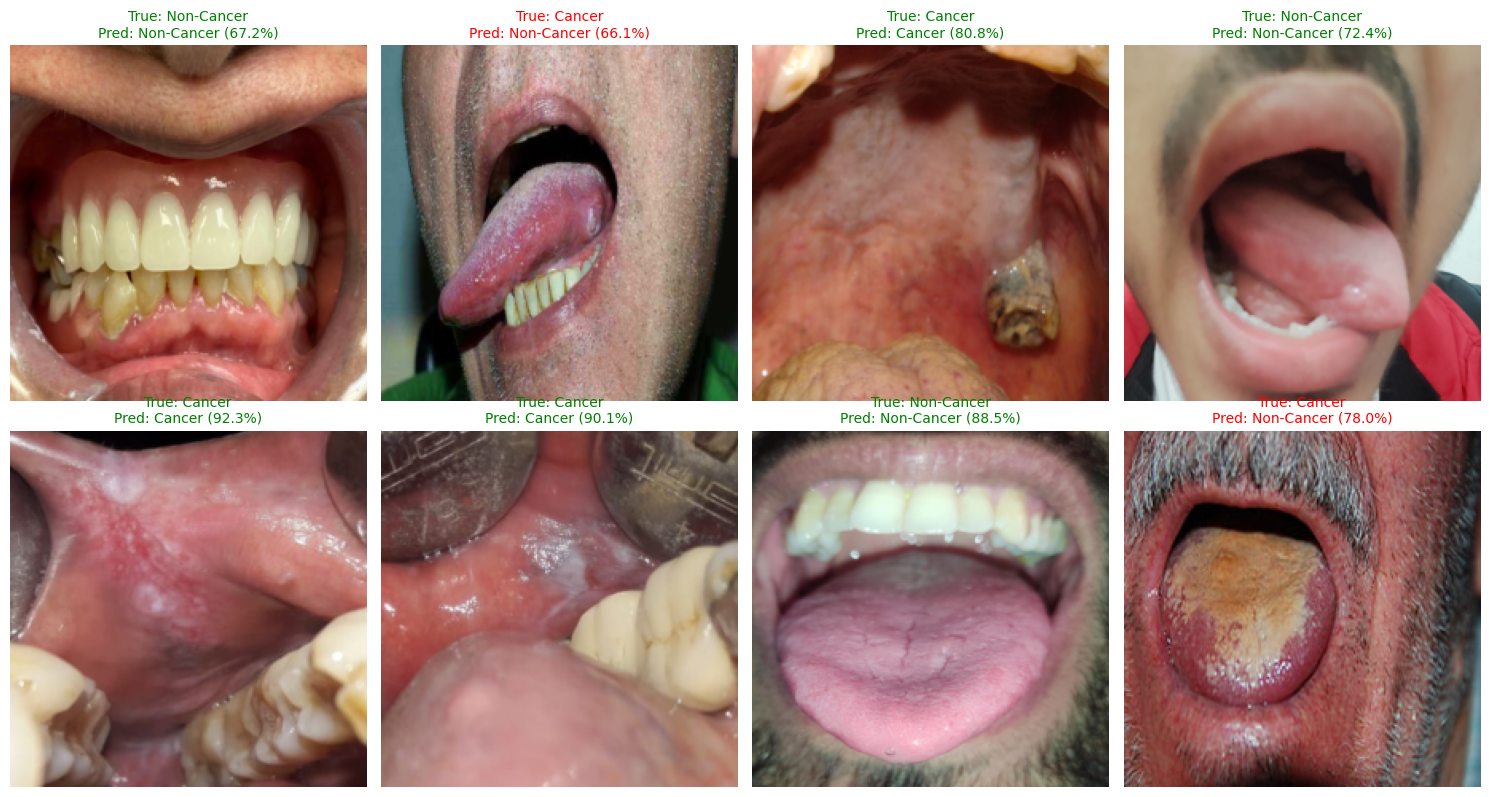


Hasil evaluasi telah disimpan ke 'evaluation_results.txt'
Gagal memuat atau mentransformasi gambar: C:\Pytorch_project\OralCancer_DatasetGabungan\Cancer\CANCER_V2_455.jpeg. Error: cannot identify image file 'C:\\Pytorch_project\\OralCancer_DatasetGabungan\\CANCER\\CANCER_V2_455.jpeg'


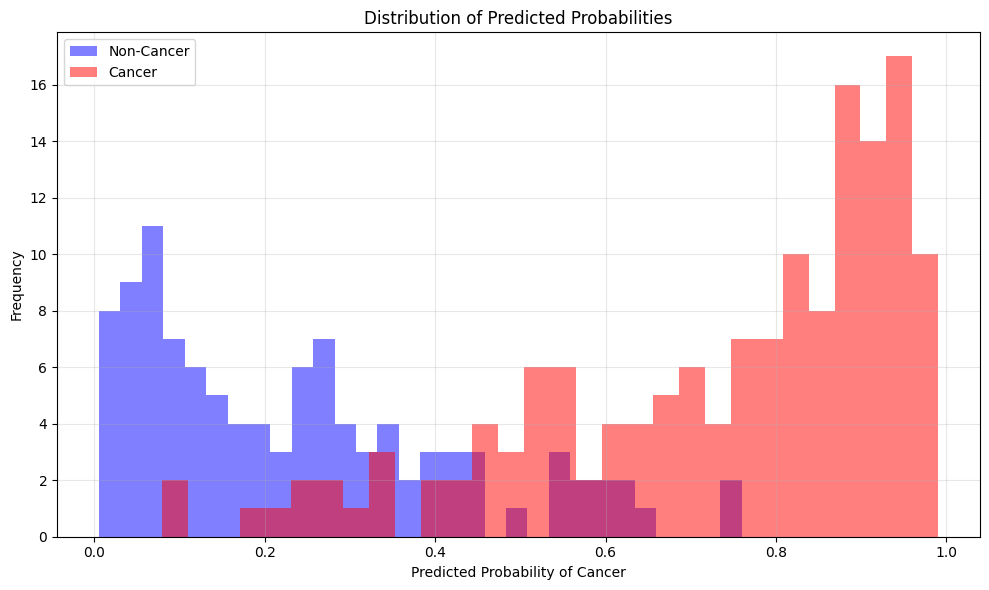


Analisis selesai! File yang dihasilkan:
1. confusion_matrix.png - Confusion matrix dengan persentase
2. sample_predictions.png - Visualisasi sampel prediksi
3. probability_distribution.png - Distribusi probabilitas prediksi
4. evaluation_results.txt - Ringkasan hasil evaluasi
5. training_history_plot.png - Grafik loss dan accuracy selama training


In [19]:
if __name__ == '__main__':
    training_history = train_and_validate_model(
        model, train_loader, val_loader, criterion, optimizer, scheduler, hyperparameters
    )

    # Plotting training history
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(training_history['train_loss'], label='Training Loss')
    plt.plot(training_history['val_loss'], label='Validation Loss')
    plt.title('Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(training_history['train_acc'], label='Training Accuracy')
    plt.plot(training_history['val_acc'], label='Validation Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('training_history_plot.png')
    plt.show()


    print("\n" + "="*50)
    print("EVALUASI MODEL PADA TEST SET")
    print("="*50)
    
    # Evaluasi model
    all_preds, all_labels, test_accuracy = evaluate_model(model, test_loader)
    
    # Nama kelas
    class_names = ['Non-Cancer', 'Cancer']
    
    # Plot confusion matrix
    cm = plot_confusion_matrix(all_labels, all_preds, class_names)
    
    # Hitung dan tampilkan metrik
    metrics = calculate_metrics(all_labels, all_preds, class_names)
    
    # Visualisasi beberapa prediksi
    print("\nMembuat visualisasi sampel prediksi...")
    visualize_predictions(model, test_dataset, num_samples=8)
    
    # Simpan hasil evaluasi ke file
    with open('evaluation_results.txt', 'w') as f:
        f.write("="*50 + "\n")
        f.write("HASIL EVALUASI MODEL ORAL CANCER DETECTION\n")
        f.write(f"Tanggal: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write("="*50 + "\n\n")
        
        f.write(f"Model: ResNet50 (Fine-tuned)\n")
        f.write(f"Total Test Samples: {len(test_dataset)}\n")
        f.write(f"Overall Accuracy: {metrics['accuracy']*100:.2f}%\n\n")
        
        f.write("Confusion Matrix:\n")
        f.write(f"{cm}\n\n")
        
        f.write("Detailed Metrics:\n")
        f.write(f"Sensitivity (Recall): {metrics['sensitivity']*100:.2f}%\n")
        f.write(f"Specificity: {metrics['specificity']*100:.2f}%\n")
        f.write(f"Precision: {metrics['precision']*100:.2f}%\n")
        f.write(f"F1-Score: {metrics['f1_score']*100:.2f}%\n")
    
    print("\nHasil evaluasi telah disimpan ke 'evaluation_results.txt'")
    
    # Plot distribusi probabilitas prediksi
    plt.figure(figsize=(10, 6))
    
    # Dapatkan probabilitas untuk analisis lebih lanjut
    model.eval()
    cancer_probs = []
    true_labels_list = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            cancer_probs.extend(probs[:, 1].cpu().numpy())  # Probabilitas untuk kelas Cancer
            true_labels_list.extend(labels.numpy())
    
    # Plot distribusi probabilitas
    cancer_probs = np.array(cancer_probs)
    true_labels_array = np.array(true_labels_list)
    
    plt.hist(cancer_probs[true_labels_array == 0], bins=30, alpha=0.5, label='Non-Cancer', color='blue')
    plt.hist(cancer_probs[true_labels_array == 1], bins=30, alpha=0.5, label='Cancer', color='red')
    plt.xlabel('Predicted Probability of Cancer')
    plt.ylabel('Frequency')
    plt.title('Distribution of Predicted Probabilities')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('probability_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nAnalisis selesai! File yang dihasilkan:")
    print("1. confusion_matrix.png - Confusion matrix dengan persentase")
    print("2. sample_predictions.png - Visualisasi sampel prediksi")
    print("3. probability_distribution.png - Distribusi probabilitas prediksi")
    print("4. evaluation_results.txt - Ringkasan hasil evaluasi")
    print("5. training_history_plot.png - Grafik loss dan accuracy selama training")

In [38]:
import warnings

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_handles = []

        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.hook_handles.append(self.target_layer.register_forward_hook(forward_hook))

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.hook_handles.append(self.target_layer.register_backward_hook(backward_hook))  # compatible & stable

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        target = output[0, class_idx]
        target.backward()

        if self.gradients is None:
            raise RuntimeError("Backward hook failed. Gradients not captured.")

        weights = self.gradients.mean(dim=[2, 3], keepdim=True)
        gradcam_map = (weights * self.activations).sum(dim=1, keepdim=True)
        gradcam_map = torch.nn.functional.relu(gradcam_map)
        gradcam_map = torch.nn.functional.interpolate(
            gradcam_map, size=input_tensor.shape[2:], mode='bilinear', align_corners=False
        )

        gradcam_map = gradcam_map.squeeze().cpu().numpy()
        gradcam_map = (gradcam_map - gradcam_map.min()) / (gradcam_map.max() - gradcam_map.min() + 1e-8)

        return gradcam_map

    def remove_hooks(self):
        for handle in self.hook_handles:
            handle.remove()


In [39]:
def show_gradcam_on_image(img_tensor, mask):
    import matplotlib.pyplot as plt
    import numpy as np
    import cv2
    import torch

    # Denormalisasi
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = img_tensor.cpu() * std + mean
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    heatmap = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    heatmap = heatmap[..., ::-1]  # Convert BGR to RGB

    cam = heatmap + img
    cam = cam / np.max(cam)

    plt.figure(figsize=(6, 6))
    plt.imshow(cam)
    plt.axis('off')
    plt.title('Grad-CAM')
    plt.tight_layout()
    plt.show()


In [42]:
# Ambil 1 gambar dari test_dataset
sample_img, _ = test_dataset[0]
input_tensor = sample_img.unsqueeze(0).to(device)

# Target layer: Conv2d terakhir dari fitur extractor
target_layer = model.features[18].conv[0]

# Inisialisasi dan generate
gradcam = GradCAM(model, target_layer=target_layer)
cam_mask = gradcam.generate(input_tensor)

# Tampilkan hasil
show_gradcam_on_image(sample_img, cam_mask)


AttributeError: 'Conv2dNormActivation' object has no attribute 'conv'

In [41]:
print(model.features[18])


Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU6(inplace=True)
)


In [43]:
def backward_hook(module, grad_input, grad_output):
    print("Gradients captured:", grad_output[0].shape)
    self.gradients = grad_output[0].detach()


In [44]:
def find_last_conv_layer(model):
    for layer in reversed(list(model.features.modules())):
        if isinstance(layer, nn.Conv2d):
            return layer
    raise ValueError("Tidak ditemukan layer Conv2d pada model.features.")


In [45]:
target_layer = find_last_conv_layer(model)
print("Target layer:", target_layer)

gradcam = GradCAM(model, target_layer=target_layer)
cam_mask = gradcam.generate(input_tensor)

show_gradcam_on_image(sample_img, cam_mask)


Target layer: Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)


RuntimeError: Backward hook failed. Gradients not captured.

In [74]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        self.model.zero_grad()
        target = output[0, class_idx]
        target.backward(retain_graph=True)

        if self.gradients is None:
            raise RuntimeError("Backward hook failed. Gradients not captured.")

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = F.interpolate(cam, size=input_tensor.shape[2:], mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


In [75]:
def show_gradcam_on_image(img_tensor, mask):
    import matplotlib.pyplot as plt
    import numpy as np

    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    heatmap = plt.cm.jet(mask)[..., :3]  # ambil RGB dari colormap
    superimposed_img = 0.6 * img + 0.4 * heatmap
    superimposed_img = np.clip(superimposed_img, 0, 1)

    plt.imshow(superimposed_img)
    plt.axis('off')
    plt.title("Grad-CAM Heatmap")
    plt.show()


In [76]:
model.eval()

# ✅ Gunakan layer Conv2d langsung
target_layer = model.features[17].conv[2]  # Conv2d(960, 320, ...)
gradcam = GradCAM(model, target_layer)

input_tensor = sample_img.unsqueeze(0).to(device)
cam_mask = gradcam.generate(input_tensor)


RuntimeError: Backward hook failed. Gradients not captured.

In [81]:
# Tampilkan CAM ke gambar asli
show_gradcam_on_image(sample_img, gradcam)


TypeError: '<' not supported between instances of 'GradCAM' and 'int'

In [55]:
print(model.features)


Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU6(inplace=True)
  )
  (1): InvertedResidual(
    (conv): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (2): InvertedResidual(
    (conv): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (

In [73]:
for name, module in model.named_modules():
    print(name, type(module))


 <class 'torchvision.models.mobilenetv2.MobileNetV2'>
features <class 'torch.nn.modules.container.Sequential'>
features.0 <class 'torchvision.ops.misc.Conv2dNormActivation'>
features.0.0 <class 'torch.nn.modules.conv.Conv2d'>
features.0.1 <class 'torch.nn.modules.batchnorm.BatchNorm2d'>
features.0.2 <class 'torch.nn.modules.activation.ReLU6'>
features.1 <class 'torchvision.models.mobilenetv2.InvertedResidual'>
features.1.conv <class 'torch.nn.modules.container.Sequential'>
features.1.conv.0 <class 'torchvision.ops.misc.Conv2dNormActivation'>
features.1.conv.0.0 <class 'torch.nn.modules.conv.Conv2d'>
features.1.conv.0.1 <class 'torch.nn.modules.batchnorm.BatchNorm2d'>
features.1.conv.0.2 <class 'torch.nn.modules.activation.ReLU6'>
features.1.conv.1 <class 'torch.nn.modules.conv.Conv2d'>
features.1.conv.2 <class 'torch.nn.modules.batchnorm.BatchNorm2d'>
features.2 <class 'torchvision.models.mobilenetv2.InvertedResidual'>
features.2.conv <class 'torch.nn.modules.container.Sequential'>
fea